In [120]:
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point, LineString, Polygon

In [63]:
# Read BasinMaker shapefile
gdf = gpd.read_file("/Users/emilito/Documents/PWA/Data/Raw/manning/Basinmaker_RoutingProduct/drainage_region_0004_00015_v2-1/finalcat_info_v2-1.shp")

# Print the first few rows of the GeoDataFrame
print(gdf.head())

     SubId  DowSubId  RivSlope    RivLength  BasSlope   BasAspect  \
0  4074178   4083168  0.000416  6487.365148  0.165625  198.563147   
1  4074179   4074257  0.001101  6811.544511  0.249594  150.588797   
2  4074180   4083134  0.000824  5095.786690  0.504006  204.616005   
3  4074181   4083226  0.001253  1995.801798  0.305813  168.984848   
4  4074182   4074895  0.010111  1176.984998  1.796100  121.198621   

        BasArea   BkfWidth  BkfDepth  Lake_Cat  ...  Seg_order     Max_DEM  \
0  8.384903e+06   2.736670  0.151112         0  ...          1  322.899994   
1  9.982588e+06   6.766825  0.260133         0  ...          1  321.600006   
2  2.312482e+07   5.016969  0.217385         0  ...          1  322.200012   
3  3.373437e+06  10.808753  0.344532         0  ...          1  323.899994   
4  1.349714e+07   1.743329  0.115290         0  ...          1  321.500000   

      Min_DEM  DA_Obs  DA_error  Obs_NM  SRC_obs  centroid_x  centroid_y  \
0  320.200012     0.0       0.0    None 

In [87]:
wsc_dp = pd.read_csv("/Users/emilito/Documents/PWA/Data/Raw/manning/WSC_data/station_metadata_historical.csv")
wsc_dp.head()

,Station ID,Station Name,Province/Territory,Basin,Latitude,Longitude,Operating Agency,Operation Schedule,Start Month,End Month,Status
0,05OE006,MANNING CANAL NEAR ILE DES CHENES,MB,5,49.63544,-96.90628,WATER SURVEY OF CANADA (DOE) (CANADA),Seasonal,MAR,OCT,Active


In [88]:
wsc_dp_gdf = gpd.GeoDataFrame(
    wsc_dp,
    geometry = gpd.points_from_xy(
        x = wsc_dp.Longitude,
        y = wsc_dp.Latitude,
        crs = 'EPSG:4326', # or: crs = pyproj.CRS.from_user_input(4326)
    )

)

wsc_dp_gdf

,Station ID,Station Name,Province/Territory,Basin,Latitude,Longitude,Operating Agency,Operation Schedule,Start Month,End Month,Status,geometry
0,05OE006,MANNING CANAL NEAR ILE DES CHENES,MB,5,49.63544,-96.90628,WATER SURVEY OF CANADA (DOE) (CANADA),Seasonal,MAR,OCT,Active,POINT (-96.90628 49.63544)


In [ ]:
#point = Point(wsc_dp_gdf.Longitude, wsc_dp_gdf.Latitude)
point = wsc_dp_gdf.geometry

gdf['contains_point'] = gdf.geometry.contains(point)

for i, row in gdf.iterrows():
    if row['contains_point'] == True:
           dp = row['SubId']
           
print(dp)

c:\Users\emilito\AppData\Local\anaconda3\envs\gpd_tutorial\lib\site-packages\geopandas\base.py:31: UserWarning: The indices of the two GeoSeries are different.
  warn("The indices of the two GeoSeries are different.")


4076245


In [121]:
for i, row in gdf.iterrows():
    if row['DowSubId'] == dp:
        sub_select = [row['DowSubId'], row['SubId']]

print(sub_select)

[4076245, 4076244]


In [122]:
n = 0
while n == 0:
    for i, row in gdf.iterrows():
        if row['DowSubId'] in sub_select and row['SubId'] not in sub_select:
            sub_select.append(row['SubId'])
            break
    else:
        n = 1
print(sub_select)

[4076245, 4076244, 4076298, 4075410, 4076349, 4076348, 4076546, 4076565, 4075680, 4075849, 4075841, 4074754, 4076027, 4076058, 4075203, 4075219, 4076596, 4076041, 4076439, 4076610, 4076611, 4075700, 4075707]


In [123]:
mc_gdf = gdf[gdf['SubId'].isin(sub_select)]

mc_gdf

,SubId,DowSubId,RivSlope,RivLength,BasSlope,BasAspect,BasArea,BkfWidth,BkfDepth,Lake_Cat,...,Max_DEM,Min_DEM,DA_Obs,DA_error,Obs_NM,SRC_obs,centroid_x,centroid_y,geometry,contains_point
558,4074754,4075841,0.001698,20253.974156,0.310443,158.167627,5.254745e+07,3.406765,0.172333,0,...,296.100006,261.700012,0.0,0.000000,None,None,-96.574245,49.434611,"POLYGON ((-96.66750 49.53292, -96.66667 49.532...",False
987,4075203,4076058,0.001921,8068.297697,0.347988,166.594009,2.989963e+07,2.580111,0.145864,0,...,285.399994,269.899994,0.0,0.000000,None,None,-96.562125,49.497314,"POLYGON ((-96.62750 49.52208, -96.62750 49.522...",False
1003,4075219,4076058,0.001876,6822.976867,0.297303,159.699433,1.988362e+07,2.110140,0.129286,0,...,283.600006,270.800018,0.0,0.000000,None,None,-96.575382,49.471902,"MULTIPOLYGON (((-96.62500 49.50125, -96.62500 ...",False
1194,4075410,4076298,0.001149,42714.472233,0.275426,163.209932,9.715021e+07,4.612039,0.206681,0,...,290.899994,241.800003,0.0,0.000000,None,None,-96.726828,49.475091,"POLYGON ((-96.87917 49.60042, -96.87667 49.600...",False
1463,4075680,4076565,0.001322,12404.700635,0.349985,172.870677,3.432867e+07,2.761900,0.151946,0,...,265.300018,248.900009,0.0,0.000000,None,None,-96.639435,49.556867,"POLYGON ((-96.73833 49.58708, -96.73583 49.587...",False
1483,4075700,4076611,0.001721,9240.832735,0.334998,143.029205,3.748232e+07,2.884175,0.155947,0,...,265.600006,249.699997,0.0,0.000000,None,None,-96.712287,49.495364,"POLYGON ((-96.74583 49.56208, -96.74583 49.563...",False
1490,4075707,4076611,0.001672,10045.340322,0.336272,148.543829,2.101546e+07,2.168515,0.131420,0,...,266.700012,249.900009,0.0,0.000000,None,None,-96.680363,49.495717,"POLYGON ((-96.73667 49.56375, -96.73667 49.564...",False
1624,4075841,4075849,0.002024,938.898024,0.351485,151.116252,3.969189e+05,4.851934,0.213066,0,...,261.800018,259.899994,0.0,0.000000,None,None,-96.668762,49.537934,"POLYGON ((-96.67417 49.53875, -96.67333 49.538...",False
1631,4075849,4076565,0.001396,7734.634127,0.248727,158.266145,2.137143e+07,5.615574,0.232595,0,...,259.899994,249.100006,0.0,0.000000,None,None,-96.694871,49.552415,"MULTIPOLYGON (((-96.66333 49.55708, -96.66333 ...",False
1808,4076027,4075849,0.002183,4123.046266,0.320509,140.569565,1.579890e+07,1.884023,0.120786,0,...,268.899994,259.899994,0.0,0.000000,None,None,-96.642648,49.484037,"POLYGON ((-96.67417 49.53875, -96.67417 49.537...",False


In [124]:
import matplotlib.pyplot as plt

(-96.95441666664995, -96.47225000034994, 49.35354166300007, 49.66979166300004)

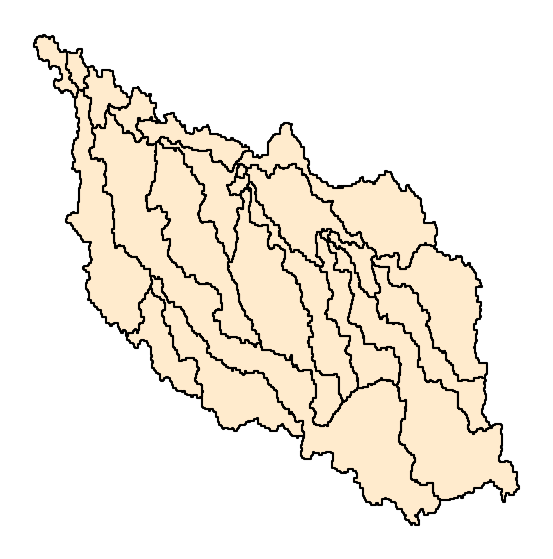

In [140]:
f, ax = plt.subplots(1,1,figsize=(7,7))

mc_gdf.plot(ax=ax, color = 'blanchedalmond', edgecolor = 'black', linewidth = 1.5)
ax.axis('off')